# 02 - Seleksi & tuning model fraud (level-hari)
**Tujuan:** memilih satu model juara + satu challenger dengan dasar yang jelas dan terdokumentasi.

**Kandidat (sengaja dibatasi):**
| Model | Peran |
|---|---|
| Logistic Regression | baseline model yang bisa dijelaskan (setara scorecard, §6.1 dokumen) |
| XGBoost | gradient boosting utama |
| HistGradientBoosting (sklearn) | implementasi boosting berbeda, pembanding robustness untuk XGBoost |

**Baseline non-model:** prior (tebakan acak), satu fitur terbaik, dan *rule gate* deterministik ala §6.3 dokumen.

**Alur:** (1) baseline -> (2) kandidat konfigurasi bawaan -> (3) tuning Optuna per model -> (4) perbandingan *di dalam* model (bawaan vs tuned) ->
(5) perbandingan *antar* model -> (6) robustness & fairness -> (7) keputusan.

**Aturan main (lihat `splits.py`):** CV 5-fold per nasabah pada DEV Okt-Jun; cek maju (train Okt-Apr -> validasi Mei-Jun); DEV Jul-Sep sebagai validasi tambahan.
Data TEST **tidak disentuh** di notebook ini (hanya di `03_final_test.ipynb`, sekali, untuk model terpilih).
Metrik utama **PR-AUC berbobot** (prevalensi asli ~0,03%), karena ROC-AUC terlalu optimistis untuk kelas sangat langka.

In [ ]:
import os
if os.path.basename(os.getcwd()) == "notebooks": os.chdir("..")      # notebooks use paths relative to the project root
print("working directory:", os.getcwd())

In [1]:
import os, sys, json, time, warnings, joblib
os.environ.setdefault("OMP_NUM_THREADS", "4")          # sisakan core supaya laptop tetap responsif
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import optuna; optuna.logging.set_verbosity(optuna.logging.WARNING)
sys.path.insert(0, os.getcwd()); import splits as S
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import QuantileTransformer, StandardScaler
from sklearn.ensemble import HistGradientBoostingClassifier
from xgboost import XGBClassifier

SMOKE = os.environ.get("SMOKE") == "1"                  # uji cepat alur, bukan hasil
N_JOBS, SEED, ALERT = 4, 42, 0.001                      # ALERT: 0,1% traffic dianggap 'alert' (kapasitas review)
TRIALS = {"LR": 8, "XGB": 20, "HGB": 12} if not SMOKE else {"LR": 2, "XGB": 2, "HGB": 2}
TUNE_FOLDS, TUNE_NEG_FRAC, N_BOOT = [0, 1, 2], 0.4, (100 if not SMOKE else 5)
ART = "artifacts"; os.makedirs(ART, exist_ok=True)
L, W = S.LABEL, S.WEIGHT

dev = S.load_dev()
for c in S.CAT: dev[c] = dev[c].astype("category")
pool, oot = S.cv_pool(dev), S.dev_oot(dev)
if SMOKE: pool, oot = pool.sample(50000, random_state=0).reset_index(drop=True), oot.sample(25000, random_state=0).reset_index(drop=True)
FEATS = S.features(dev); CAT = [c for c in S.CAT if c in FEATS]; NUM = [c for c in FEATS if c not in CAT]
folds = S.cv_folds(pool)
prev = np.average(pool[L], weights=pool[W])
print(f"fitur {len(FEATS)} (numerik {len(NUM)}, kategorikal {len(CAT)}) | pool {len(pool):,} | dev-OOT {len(oot):,} | prevalensi asli {prev:.4%} | SMOKE={SMOKE}")

fitur 68 (numerik 64, kategorikal 4) | pool 359,008 | dev-OOT 129,799 | prevalensi asli 0.0348% | SMOKE=False


In [2]:
def metrics(y, s, w, alert=ALERT):
    o = np.argsort(-s); ys, ws = y[o], w[o]
    k = np.searchsorted(np.cumsum(ws), alert * ws.sum())
    tp = (ys[:k] * ws[:k]).sum()
    return dict(PR_AUC=average_precision_score(y, s, sample_weight=w), ROC_AUC=roc_auc_score(y, s, sample_weight=w),
                recall_at_alert=tp / (ys * ws).sum(), precision_at_alert=tp / ws[:k].sum())

DEFAULTS = {
    "LR":  dict(C=0.3, class_weight="balanced", transform="quantile"),
    "XGB": dict(n_estimators=300, learning_rate=0.05, max_depth=5, subsample=0.8, colsample_bytree=0.8, min_child_weight=5.0, reg_lambda=1.0, gamma=0.0),
    "HGB": dict(max_iter=300, learning_rate=0.05, max_leaf_nodes=31, min_samples_leaf=20, l2_regularization=1e-3, max_features=1.0),
}

class Model:
    def __init__(self, name, params, seed=SEED): self.name, self.p, self.seed = name, dict(params), seed
    def fit(self, df, y):
        p = self.p
        if self.name == "LR":
            tr = QuantileTransformer(n_quantiles=200, output_distribution="normal") if p["transform"] == "quantile" else StandardScaler()
            self.m = make_pipeline(SimpleImputer(strategy="median"), tr,
                                   LogisticRegression(C=p["C"], class_weight=p["class_weight"], max_iter=3000)).fit(df[NUM], y)
        elif self.name == "XGB":
            self.m = XGBClassifier(tree_method="hist", enable_categorical=True, n_jobs=N_JOBS, random_state=self.seed, **p).fit(df[FEATS], y)
        else:
            self.m = HistGradientBoostingClassifier(categorical_features="from_dtype", early_stopping=False, random_state=self.seed, **p).fit(df[FEATS], y)
        return self
    def score(self, df): return self.m.predict_proba(df[NUM] if self.name == "LR" else df[FEATS])[:, 1]

def cv_eval(name, params, idx=None, neg_frac=1.0, seed=SEED):
    rng, rows = np.random.default_rng(seed), []
    for k in (range(len(folds)) if idx is None else idx):
        a, b = folds[k]; tr, va = pool.iloc[a], pool.iloc[b]
        if neg_frac < 1: tr = tr[(tr[L] == 1) | (rng.random(len(tr)) < neg_frac)]
        s = Model(name, params, seed).fit(tr, tr[L].values).score(va)
        rows.append(dict(fold=k, **metrics(va[L].values, s, va[W].values)))
    return pd.DataFrame(rows).set_index("fold")

def fmt(df, cols=("PR_AUC", "ROC_AUC", "recall_at_alert", "precision_at_alert")):
    return pd.Series({c: f"{df[c].mean():.3f} ± {df[c].std():.3f}" for c in cols})

## 1. Baseline non-model
Prior = tebakan tanpa informasi (PR-AUC = prevalensi). *Rule gate* meniru pemeriksaan deterministik §6.3 (device baru, ganti kredensial, payee baru bernilai besar, night velocity, geo mismatch, rasio outflow/saldo).

In [3]:
def rule_gate(d):
    hits = ((d.new_device_7 > 0).astype(int) + (d.cred_change_3 > 0) + (d.ftp_large_7 > 0) + (d.night_share_7 > 0.3)
            + (d.geo_mismatch_share_7 > 0.5) + (d.out_to_balance_max_3d > 0.5) + (d.new_payee_cnt_7 >= 2))
    return hits.values + 0.01 * d.out_to_balance_1.values          # pemutus seri, bukan bagian aturan

# satu fitur terbaik (dipilih di pool; sedikit optimistis, tidak apa-apa untuk baseline)
single = {f: average_precision_score(pool[L], pool[f].fillna(pool[f].median()), sample_weight=pool[W]) for f in NUM}
best_f = max(single, key=single.get); print("fitur tunggal terbaik:", best_f, round(single[best_f], 4))

base_rows = {}
for name, fn in {"prior": lambda d: np.zeros(len(d)), "satu_fitur_terbaik": lambda d: d[best_f].fillna(pool[best_f].median()).values, "rule_gate_6.3": rule_gate}.items():
    rows = []
    for k, (a, b) in enumerate(folds):
        va = pool.iloc[b]; s = fn(va) if name != "prior" else np.random.default_rng(k).random(len(va))
        rows.append(metrics(va[L].values, s, va[W].values))
    base_rows[name] = fmt(pd.DataFrame(rows))
baselines = pd.DataFrame(base_rows).T; baselines

fitur tunggal terbaik: max_out_7_to_income 0.0415


,PR_AUC,ROC_AUC,recall_at_alert,precision_at_alert
prior,0.000 ± 0.000,0.498 ± 0.005,0.002 ± 0.001,0.001 ± 0.001
satu_fitur_terbaik,0.049 ± 0.014,0.854 ± 0.014,0.118 ± 0.019,0.041 ± 0.010
rule_gate_6.3,0.017 ± 0.007,0.861 ± 0.008,0.069 ± 0.007,0.024 ± 0.004


## 2. Kandidat dengan konfigurasi bawaan (CV 5-fold)

In [4]:
t0 = time.time(); default_cv = {}
for n in ("LR", "XGB", "HGB"):
    default_cv[n] = cv_eval(n, DEFAULTS[n]); print(f"{n} selesai ({time.time() - t0:.0f}s)")
stage2 = pd.DataFrame({f"{n} (bawaan)": fmt(d) for n, d in default_cv.items()}).T
pd.concat([baselines, stage2])

LR selesai (116s)


XGB selesai (192s)


HGB selesai (285s)


,PR_AUC,ROC_AUC,recall_at_alert,precision_at_alert
prior,0.000 ± 0.000,0.498 ± 0.005,0.002 ± 0.001,0.001 ± 0.001
satu_fitur_terbaik,0.049 ± 0.014,0.854 ± 0.014,0.118 ± 0.019,0.041 ± 0.010
rule_gate_6.3,0.017 ± 0.007,0.861 ± 0.008,0.069 ± 0.007,0.024 ± 0.004
LR (bawaan),0.109 ± 0.030,0.972 ± 0.003,0.263 ± 0.039,0.094 ± 0.024
XGB (bawaan),0.756 ± 0.052,0.998 ± 0.001,0.842 ± 0.028,0.295 ± 0.040
HGB (bawaan),0.763 ± 0.051,0.998 ± 0.001,0.847 ± 0.029,0.296 ± 0.037


## 3. Tuning hyperparameter (Optuna, TPE)
* Tiap model dituning pada **fold 0-2** dengan 40% negatif (hemat waktu laptop); objektif = PR-AUC rata-rata.
* Konfigurasi bawaan dimasukkan sebagai trial pertama, jadi tuning tidak mungkin lebih buruk dari bawaan di fold tuning.
* **Fold 3-4 tidak dipakai tuning** -> dipakai di bagian 4 untuk mendeteksi *overfitting ke tuning*.

memakai hasil tuning tersimpan dari eksekusi pertama


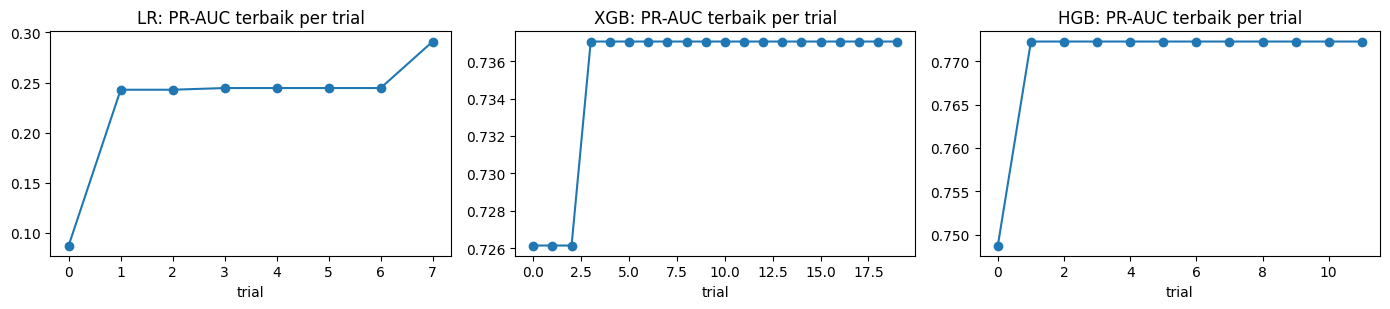

,C,class_weight,transform,n_estimators,learning_rate,max_depth,subsample,colsample_bytree,min_child_weight,reg_lambda,gamma,max_iter,max_leaf_nodes,min_samples_leaf,l2_regularization,max_features
LR,0.269265,None,standard,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
XGB,NaN,NaN,NaN,200.0,0.081184,5.0,0.716492,0.805926,1.518748,0.470147,1.831809,NaN,NaN,NaN,NaN,NaN
HGB,NaN,NaN,NaN,NaN,0.182147,NaN,NaN,NaN,NaN,NaN,NaN,250.0,50.0,128.0,0.004208,0.577997


In [5]:
def space(name, t):
    if name == "LR":
        return dict(C=t.suggest_float("C", 1e-3, 10, log=True), class_weight=t.suggest_categorical("class_weight", [None, "balanced"]),
                    transform=t.suggest_categorical("transform", ["quantile", "standard"]))
    if name == "XGB":
        return dict(n_estimators=t.suggest_int("n_estimators", 100, 500, step=50), learning_rate=t.suggest_float("learning_rate", 0.03, 0.2, log=True),
                    max_depth=t.suggest_int("max_depth", 3, 8), subsample=t.suggest_float("subsample", 0.6, 1.0),
                    colsample_bytree=t.suggest_float("colsample_bytree", 0.5, 1.0), min_child_weight=t.suggest_float("min_child_weight", 1, 20, log=True),
                    reg_lambda=t.suggest_float("reg_lambda", 0.1, 20, log=True), gamma=t.suggest_float("gamma", 0, 5))
    return dict(max_iter=t.suggest_int("max_iter", 100, 500, step=50), learning_rate=t.suggest_float("learning_rate", 0.03, 0.2, log=True),
                max_leaf_nodes=t.suggest_int("max_leaf_nodes", 15, 63), min_samples_leaf=t.suggest_int("min_samples_leaf", 20, 200),
                l2_regularization=t.suggest_float("l2_regularization", 1e-3, 10, log=True), max_features=t.suggest_float("max_features", 0.5, 1.0))

def run_tuning():
    studies, best = {}, {}
    for n in ("LR", "XGB", "HGB"):
        t0 = time.time()
        def obj(trial, n=n):
            df = cv_eval(n, space(n, trial), idx=TUNE_FOLDS, neg_frac=TUNE_NEG_FRAC)
            trial.set_user_attr("std", float(df.PR_AUC.std())); return df.PR_AUC.mean()
        st = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
        st.enqueue_trial(DEFAULTS[n]); st.optimize(obj, n_trials=TRIALS[n])
        studies[n], best[n] = st, {**DEFAULTS[n], **st.best_params}
        st.trials_dataframe().to_csv(f"{ART}/tuning_{n}.csv", index=False)
        print(f"{n}: {TRIALS[n]} trial, {time.time() - t0:.0f}s | trial bawaan {st.trials[0].value:.4f} -> terbaik {st.best_value:.4f}")
    json.dump(best, open(f"{ART}/best_params.json", "w"), indent=1)
    return best

# hasil tuning dipakai ulang bila sudah ada (TPE ber-seed tetap; RETUNE=1 untuk mengulang dari awal)
if os.path.exists(f"{ART}/best_params.json") and os.environ.get("RETUNE") != "1" and not SMOKE:
    best = json.load(open(f"{ART}/best_params.json")); print("memakai hasil tuning tersimpan dari eksekusi pertama")
else:
    best = run_tuning()
fig, ax = plt.subplots(1, 3, figsize=(14, 3.2))
for a, n in zip(ax, ("LR", "XGB", "HGB")):
    v = pd.read_csv(f"{ART}/tuning_{n}.csv")["value"].values; a.plot(np.maximum.accumulate(v), "o-"); a.set_title(f"{n}: PR-AUC terbaik per trial"); a.set_xlabel("trial")
plt.tight_layout(); plt.show()
pd.DataFrame(best).T

## 4. Perbandingan *di dalam* model: bawaan vs tuned (CV 5-fold penuh)
Kolom `fold 3-4` = fold yang **tidak** dipakai saat tuning, sehingga jujur menunjukkan apakah tuning benar-benar menolong.

In [6]:
tuned_cv, rows = {}, []
for n in ("LR", "XGB", "HGB"):
    tuned_cv[n] = cv_eval(n, best[n])
    d0, d1 = default_cv[n].PR_AUC, tuned_cv[n].PR_AUC
    rows.append(dict(model=n, PR_default=d0.mean(), PR_tuned=d1.mean(), delta_semua_fold=(d1 - d0).mean(), delta_fold_3_4=(d1 - d0).loc[[3, 4]].mean(),
                     fold_membaik=f"{int(((d1 - d0) > 0).sum())}/5"))
within = pd.DataFrame(rows).set_index("model").round(4)
# ATURAN: konfigurasi tuned dipakai hanya jika terbukti menolong di fold yang TIDAK dipakai tuning (3-4), rata-rata semua fold,
# dan konsisten (membaik di >= 4 dari 5 fold). Kalau tidak, konfigurasi bawaan dipertahankan (tuning dianggap overfit ke noise).
final_cfg, chosen_cv, rule_rows = {}, {}, []
for n in ("LR", "XGB", "HGB"):
    r = within.loc[n]; ok = (r.delta_semua_fold > 0) and (r.delta_fold_3_4 > 0) and (int(r.fold_membaik.split("/")[0]) >= 4)
    final_cfg[n], chosen_cv[n] = (best[n], tuned_cv[n]) if ok else (DEFAULTS[n], default_cv[n])
    rule_rows.append(dict(model=n, konfigurasi_final="tuned" if ok else "bawaan"))
within.join(pd.DataFrame(rule_rows).set_index("model"))

,PR_default,PR_tuned,delta_semua_fold,delta_fold_3_4,fold_membaik,konfigurasi_final
model,,,,,,
LR,0.1094,0.3225,0.2131,0.2116,5/5,tuned
XGB,0.7563,0.7446,-0.0117,-0.0014,1/5,bawaan
HGB,0.7625,0.6985,-0.0641,-0.0088,1/5,bawaan


## 5. Perbandingan *antar* model (konfigurasi final tiap model)
Tiga sudut pandang: CV 5-fold, uji maju waktu (train Okt-Apr -> validasi Mei-Jun), dan DEV-OOT Jul-Sep (model dilatih pada seluruh pool).

In [7]:
a_f, b_f = S.forward_split(pool); fit_fwd = pool.iloc[a_f], pool.iloc[b_f]
fitted, scores_oot, res = {}, {}, {}
for n in ("LR", "XGB", "HGB"):
    m_f = Model(n, final_cfg[n]).fit(fit_fwd[0], fit_fwd[0][L].values)
    fwd = metrics(fit_fwd[1][L].values, m_f.score(fit_fwd[1]), fit_fwd[1][W].values)
    fitted[n] = Model(n, final_cfg[n]).fit(pool, pool[L].values)            # dilatih pada seluruh pool, dibekukan sebagai kandidat
    scores_oot[n] = fitted[n].score(oot)
    o = metrics(oot[L].values, scores_oot[n], oot[W].values)
    res[n] = dict(CV_PR=chosen_cv[n].PR_AUC.mean(), CV_PR_std=chosen_cv[n].PR_AUC.std(), CV_ROC=chosen_cv[n].ROC_AUC.mean(), CV_recall=chosen_cv[n].recall_at_alert.mean(),
                  FWD_PR=fwd["PR_AUC"], OOT_PR=o["PR_AUC"], OOT_ROC=o["ROC_AUC"], OOT_recall=o["recall_at_alert"], OOT_precision=o["precision_at_alert"])
compare = pd.DataFrame(res).T.round(4); compare

,CV_PR,CV_PR_std,CV_ROC,CV_recall,FWD_PR,OOT_PR,OOT_ROC,OOT_recall,OOT_precision
LR,0.3225,0.0638,0.9534,0.4437,0.2799,0.2090,0.9539,0.3752,0.0938
XGB,0.7563,0.0523,0.9983,0.8418,0.7093,0.6994,0.9987,0.8508,0.2122
HGB,0.7625,0.0507,0.9984,0.8470,0.7195,0.6607,0.9988,0.8480,0.2117


In [8]:
# interval kepercayaan bootstrap PER NASABAH (bukan per baris) pada DEV-OOT, dan selisih berpasangan antar model
cust_codes, n_c = pd.factorize(oot.customer_id)[0], oot.customer_id.nunique()
rng = np.random.default_rng(SEED); boots = {n: [] for n in scores_oot}; boots["rule_gate_6.3"] = []; scores_oot["rule_gate_6.3"] = rule_gate(oot)
for _ in range(N_BOOT):
    wb = oot[W].values * np.bincount(rng.integers(0, n_c, n_c), minlength=n_c)[cust_codes]
    for n, s in scores_oot.items(): boots[n].append(average_precision_score(oot[L].values, s, sample_weight=wb))
B = pd.DataFrame(boots)
ci = pd.DataFrame({"PR_AUC": {n: average_precision_score(oot[L], s, sample_weight=oot[W]) for n, s in scores_oot.items()},
                   "CI95_low": B.quantile(0.025), "CI95_high": B.quantile(0.975)}).round(4)
diff = pd.DataFrame({f"{a} - {b}": (B[a] - B[b]).quantile([0.025, 0.5, 0.975]).values for a, b in (("XGB", "HGB"), ("XGB", "LR"), ("HGB", "LR"), ("XGB", "rule_gate_6.3"))}, index=["2.5%", "median", "97.5%"]).round(4)
display(ci); print("Selisih PR-AUC berpasangan (CI yang tidak melewati 0 = beda nyata):"); display(diff)

,PR_AUC,CI95_low,CI95_high
LR,0.2090,0.1355,0.2946
XGB,0.6994,0.6098,0.7834
HGB,0.6607,0.5535,0.7610
rule_gate_6.3,0.0091,0.0043,0.0161


Selisih PR-AUC berpasangan (CI yang tidak melewati 0 = beda nyata):


,XGB - HGB,XGB - LR,HGB - LR,XGB - rule_gate_6.3
2.5%,-0.0018,0.4342,0.3748,0.5992
median,0.0382,0.4961,0.4563,0.6998
97.5%,0.0749,0.5725,0.5540,0.7738


## 6. Robustness & fairness (model tuned, DEV-OOT)

In [9]:
GROUPS = {
  "device":   [c for c in FEATS if c.startswith(("new_device", "cred_change", "device_cnt"))],
  "geo":      [c for c in FEATS if c.startswith("geo_mismatch")],
  "merchant": [c for c in FEATS if c.startswith("mix_")],
  "payee":    [c for c in FEATS if c.startswith(("new_payee", "distinct", "payee_concentration", "top_payee", "ftp_large"))],
  "malam":    [c for c in FEATS if c.startswith("night_share")],
  "saldo/pass-through": [c for c in FEATS if c.startswith(("passthrough", "out_to_in", "out_to_balance", "min_balance", "balance", "days_low"))],
  "profil":   [c for c in ("declared_income", "age_ord", "gender", "region", "occupation", "segment", "shared_device_flag", "tenure_months", "kyc_age_months") if c in FEATS],
}
pr = lambda d, n: average_precision_score(d[L], fitted[n].score(d), sample_weight=d[W])
base_pr = {n: pr(oot, n) for n in fitted}; rob = {}
def blank(d, cols):                                          # kosongkan kolom tanpa mengubah dtype (kategori tetap kategori)
    for c in cols: d[c] = pd.Categorical([np.nan] * len(d), categories=d[c].cat.categories) if c in CAT else np.nan
    return d
for g, cols in GROUPS.items():                              # fitur satu grup 'hilang' saat scoring (sensor mati / data tidak tersedia)
    rob[f"tanpa {g}"] = {n: pr(blank(oot.copy(), cols), n) / base_pr[n] for n in fitted}
r = np.random.default_rng(1); d = oot.copy()
for c in FEATS: d.loc[r.random(len(d)) < 0.2, c] = np.nan
rob["20% nilai hilang acak"] = {n: pr(d, n) / base_pr[n] for n in fitted}
d = oot.copy(); d[NUM] = d[NUM].astype("float64") * np.exp(r.normal(0, 0.15, (len(d), len(NUM)))); rob["noise lognormal 15%"] = {n: pr(d, n) / base_pr[n] for n in fitted}
robust = pd.DataFrame(rob).T.round(3); print("Retensi PR-AUC (1.0 = tidak berubah):"); display(robust)
seed_rows = {n: [average_precision_score(oot[L], Model(n, final_cfg[n], seed=s).fit(pool, pool[L].values).score(oot), sample_weight=oot[W]) for s in (1, 2, 3)] for n in ("XGB", "HGB")}
print("Stabilitas antar random seed (PR-AUC DEV-OOT):", {n: f"{np.mean(v):.4f} ± {np.std(v):.4f}" for n, v in seed_rows.items()})

Retensi PR-AUC (1.0 = tidak berubah):


,LR,XGB,HGB
tanpa device,0.867,0.801,0.960
tanpa geo,0.982,0.976,1.006
tanpa merchant,0.756,0.756,0.885
tanpa payee,0.349,0.426,0.522
tanpa malam,0.896,0.867,0.802
tanpa saldo/pass-through,0.561,0.761,0.774
tanpa profil,1.013,0.650,0.730
20% nilai hilang acak,0.401,0.206,0.507
noise lognormal 15%,0.784,0.483,0.601


Stabilitas antar random seed (PR-AUC DEV-OOT): {'XGB': '0.6599 ± 0.0141', 'HGB': '0.6748 ± 0.0078'}


In [10]:
# Recall per tipe fraud (termasuk stealth) dan fairness pada ambang yang sama (ALERT = 0,1% traffic)
rows, fair = [], []
for n in fitted:
    s = scores_oot[n]; thr = np.sort(s)[::-1][np.searchsorted(np.cumsum(oot[W].values[np.argsort(-s)]), ALERT * oot[W].sum())]
    flag = s >= thr; p = oot[L].values == 1
    for (t, st_), g in oot[p].assign(f=flag[p]).groupby(["_fraud_type", "_stealth"]): rows.append(dict(model=n, tipe=t, stealth=st_, n=len(g), recall=g.f.mean()))
    for col in ("gender", "age_ord"):
        for v, g in oot.assign(f=flag).groupby(col):
            gp = g[g[L] == 1]; fair.append(dict(model=n, group=f"{col}={v}", flag_rate=np.average(g.f, weights=g[W]), recall=gp.f.mean() if len(gp) else np.nan, n_pos=len(gp)))
bytype = pd.DataFrame(rows).pivot_table(index=["tipe", "stealth"], columns="model", values="recall").round(3); display(bytype)
fairness = pd.DataFrame(fair).pivot_table(index="group", columns="model", values=["flag_rate", "recall"]).round(4); display(fairness)

model           HGB     LR    XGB
tipe stealth                     
ato  0        0.903  0.758  0.887
     1        0.587  0.022  0.370
mule 0        0.892  0.729  0.900
     1        0.772  0.253  0.833
scam 0        0.955  0.370  0.940
     1        0.842  0.017  0.819

flag_rate                  recall                
model           HGB      LR     XGB     HGB      LR     XGB
group                                                      
age_ord=0    0.0011  0.0008  0.0013  0.8122  0.3493  0.8734
age_ord=1    0.0010  0.0009  0.0011  0.8198  0.4084  0.8198
age_ord=2    0.0009  0.0012  0.0007  0.8964  0.4041  0.8497
age_ord=3    0.0011  0.0009  0.0009  0.8703  0.3784  0.8811
age_ord=4    0.0009  0.0013  0.0012  0.8810  0.2857  0.8492
gender=F     0.0011  0.0012  0.0010  0.8503  0.3839  0.8445
gender=M     0.0009  0.0008  0.0010  0.8459  0.3670  0.8569

## 7. Keputusan
**Aturan pemilihan (ditetapkan sebelum melihat hasil akhir):**
1. Juara = PR-AUC CV tertinggi di antara konfigurasi final tiap model (tuned hanya jika lolos aturan bagian 4, selain itu bawaan).
2. *Aturan 1-standard-error*: jika ada model yang lebih sederhana/mudah dijelaskan dengan PR-AUC dalam 1 SE dari juara, pilih yang sederhana (LR < HGB < XGB dalam urutan kesederhanaan).
3. Challenger = model terbaik berikutnya dari **keluarga berbeda**.
4. Pastikan juara tidak kalah nyata dari rule gate dan tidak runtuh pada uji robustness (retensi minimal 0,5 pada ablasi satu grup).

In [11]:
order = {"LR": 0, "HGB": 1, "XGB": 2}
cv = compare[["CV_PR", "CV_PR_std"]].assign(se=lambda d: d.CV_PR_std / np.sqrt(5))
top = cv.CV_PR.idxmax(); within_1se = [n for n in cv.index if cv.CV_PR[n] >= cv.CV_PR[top] - cv.se[top]]
champion = min(within_1se, key=lambda n: order[n])
challenger = max([n for n in cv.index if n != champion], key=lambda n: cv.CV_PR[n])
worst = robust.drop(index=["20% nilai hilang acak", "noise lognormal 15%"]).min()
summary = compare.assign(worst_ablation=worst.round(3), jelas_lebih_baik_dari_rule=[bool(B["rule_gate_6.3"].quantile(.975) < B[n].quantile(.025)) for n in compare.index])
print(f"PR-AUC CV tertinggi: {top} | dalam 1 SE: {within_1se} -> JUARA = {champion}, CHALLENGER = {challenger}")
summary.round(4)

PR-AUC CV tertinggi: HGB | dalam 1 SE: ['XGB', 'HGB'] -> JUARA = HGB, CHALLENGER = XGB


,CV_PR,CV_PR_std,CV_ROC,CV_recall,FWD_PR,OOT_PR,OOT_ROC,OOT_recall,OOT_precision,worst_ablation,jelas_lebih_baik_dari_rule
LR,0.3225,0.0638,0.9534,0.4437,0.2799,0.2090,0.9539,0.3752,0.0938,0.349,True
XGB,0.7563,0.0523,0.9983,0.8418,0.7093,0.6994,0.9987,0.8508,0.2122,0.426,True
HGB,0.7625,0.0507,0.9984,0.8470,0.7195,0.6607,0.9988,0.8480,0.2117,0.522,True


In [12]:
# Bekukan: model (dilatih pada pool), parameter, fitur, ambang pita (dihitung dari DEV-OOT, bukan TEST)
def calibrate(p, k=S.NEG_KEEP): return p * k / (p * k + (1 - p))
from sklearn.metrics import precision_recall_curve
def bands(y, s, w, prec_sus=0.05, prec_high=0.5):
    pr_, rc_, th = precision_recall_curve(y, s, sample_weight=w)
    first = lambda t: th[np.argmax(pr_[:-1] >= t)] if (pr_[:-1] >= t).any() else th[-1]
    return float(min(first(prec_sus), first(prec_high))), float(first(prec_high))
os.makedirs("models", exist_ok=True); frozen = {}
for role, n in (("champion", champion), ("challenger", challenger)):
    cal = calibrate(scores_oot[n]); t_s, t_h = bands(oot[L].values, cal, oot[W].values)
    joblib.dump(fitted[n], f"models/{role}.joblib")
    frozen[role] = dict(model=n, params=final_cfg[n], config="tuned" if final_cfg[n] is best[n] else "bawaan", thr_suspicious=t_s, thr_high_risk=t_h, oot_pr_auc=float(compare.loc[n, "OOT_PR"]))
json.dump(dict(frozen=frozen, features=FEATS, numeric=NUM, categorical=CAT, alert_rate=ALERT, neg_keep=S.NEG_KEEP,
               cv_pr_auc=compare.CV_PR.round(4).to_dict(), rule="juara = CV PR-AUC tertinggi + aturan 1-SE; challenger = keluarga berbeda"),
          open(f"{ART}/selection.json", "w"), indent=1)
summary.round(4).to_csv(f"{ART}/model_comparison.csv"); print("tersimpan:", sorted(os.listdir("models")), sorted(os.listdir(ART))); frozen

tersimpan: ['challenger.joblib', 'champion.joblib'] ['best_params.json', 'model_comparison.csv', 'selection.json', 'tuning_HGB.csv', 'tuning_LR.csv', 'tuning_XGB.csv']


{'champion': {'model': 'HGB',
  'params': {'max_iter': 300,
   'learning_rate': 0.05,
   'max_leaf_nodes': 31,
   'min_samples_leaf': 20,
   'l2_regularization': 0.001,
   'max_features': 1.0},
  'config': 'bawaan',
  'thr_suspicious': 0.0010253406758091567,
  'thr_high_risk': 0.05948750036050261,
  'oot_pr_auc': 0.6607},
 'challenger': {'model': 'XGB',
  'params': {'n_estimators': 300,
   'learning_rate': 0.05,
   'max_depth': 5,
   'subsample': 0.8,
   'colsample_bytree': 0.8,
   'min_child_weight': 5.0,
   'reg_lambda': 1.0,
   'gamma': 0.0},
  'config': 'bawaan',
  'thr_suspicious': 0.002326394198462367,
  'thr_high_risk': 0.04233397915959358,
  'oot_pr_auc': 0.6994}}

## Catatan metodologi (temuan eksekusi pertama)
Pada eksekusi pertama, seluruh konfigurasi hasil tuning dipakai begitu saja. Hasilnya menunjukkan **tuning pada tiga fold dengan 40% negatif terlalu noisy**
(simpangan PR-AUC antar fold ~0,05, sehingga optimizer mengejar noise):
* XGBoost tuned: PR-AUC DEV-OOT 0,61 vs 0,70 untuk konfigurasi bawaan (seed sama).
* HGB tuned (`learning_rate` 0,18, `max_features` 0,58): 0,63 pada seed 42, tetapi **0,02-0,05 pada seed 1 dan 2** -> konfigurasi tidak stabil, hanya 'beruntung' di satu seed. HGB bawaan stabil (0,66 / 0,69).
* LR tuned membaik besar dan konsisten (5/5 fold) karena transformasi `standard` jauh lebih cocok daripada `quantile` untuk data ini.

Karena itu aturan di bagian 4 ditambahkan: tuned dipakai hanya bila terbukti menolong di fold yang tidak dipakai tuning dan konsisten.
Implikasinya: lanskap hyperparameter model boosting pada data ini relatif datar di sekitar nilai bawaan; kenaikan dari tuning lebih kecil daripada noise evaluasi.